# 03 · Data quality, cleaning and exploration

1. **Data quality and cleaning**: what is wrong or unusual in the data, and what we do about it.
2. **Exploration** of the cleaned data: sales trends, product performance, category performance, and
   customer/product behaviour. Seasonality is covered in notebook 02.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_science").is_dir())
sys.path.insert(0, str(ROOT))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from data_science.data import load_articles, load_transactions, NON_FASHION_GROUPS, UNKNOWN_VALUES
from data_science.features.style import STYLE_ATTRIBUTES, add_style_columns

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

raw_articles = load_articles(clean=False)
tx_raw = load_transactions()
print(f"raw: {len(raw_articles):,} articles, {len(tx_raw):,} transactions")

raw: 105,542 articles, 31,788,324 transactions


## 1. Data quality

### 1.1 Articles

In [2]:
checks = {
    "duplicate article_id": raw_articles.article_id.duplicated().sum(),
    "product_code ≠ first 7 digits of article_id": (raw_articles.article_id.astype(str).str.zfill(10).str[:7] != raw_articles.product_code).sum(),
    "missing detail_desc": raw_articles.detail_desc.isna().sum(),
    "non-fashion product group": raw_articles.product_group_name.isin(NON_FASHION_GROUPS).sum(),
}
for col in STYLE_ATTRIBUTES:
    checks[f"unknown/undefined {col}"] = raw_articles[col].astype(str).str.lower().isin(UNKNOWN_VALUES).sum()
pd.Series(checks, name="articles").to_frame()

,articles
duplicate article_id,0
product_code ≠ first 7 digits of article_id,0
missing detail_desc,416
non-fashion product group,98
unknown/undefined index_group_name,0
unknown/undefined product_type_name,121
unknown/undefined graphical_appearance_name,52
unknown/undefined colour_group_name,28
unknown/undefined perceived_colour_value_name,133


In [3]:
# case-only spelling variants inside style attributes (handled in add_style_columns)
for col in STYLE_ATTRIBUTES:
    v = pd.Series(raw_articles[col].unique())
    dup = v.groupby(v.str.lower()).filter(lambda g: len(g) > 1)
    if len(dup):
        print(f"{col}: {sorted(dup)}")

product_type_name: ['Dog Wear', 'Dog wear']


### 1.2 Transactions

In [4]:
all_days = pd.date_range(tx_raw.t_dat.min(), tx_raw.t_dat.max())
article_max = tx_raw.groupby("article_id").price.transform("max")
rel_price = tx_raw.price / article_max
customer_day = tx_raw.groupby(["customer_id", "t_dat"]).price.agg(["size", "sum"])
total_rev = tx_raw.price.sum()

tx_checks = pd.DataFrame([
    ("missing values", tx_raw.isna().sum().sum(), None),
    ("days with no transactions", len(all_days.difference(tx_raw.t_dat.unique())), None),
    ("article_id not in articles.csv", (~tx_raw.article_id.isin(raw_articles.article_id)).sum(), None),
    ("price ≤ 0", (tx_raw.price <= 0).sum(), None),
    ("identical rows (same day, customer, article, price, channel)",
     tx_raw.duplicated(["t_dat", "customer_id", "article_id", "price", "sales_channel_id"]).sum(), None),
    ("price < 10% of the article's highest price", (rel_price < .1).sum(), tx_raw.price[rel_price < .1].sum() / total_rev),
    ("customer-days with > 50 units", (customer_day["size"] > 50).sum(),
     customer_day.loc[customer_day["size"] > 50, "sum"].sum() / total_rev),
], columns=["check", "rows", "share of revenue"])
tx_checks["share of rows"] = tx_checks.rows / len(tx_raw)
tx_checks.style.format({"rows": "{:,}", "share of revenue": "{:.3%}", "share of rows": "{:.3%}"}, na_rep="")

,check,rows,share of revenue,share of rows
0,missing values,0,,0.000%
1,days with no transactions,0,,0.000%
2,article_id not in articles.csv,0,,0.000%
3,price ≤ 0,0,,0.000%
4,"identical rows (same day, customer, article, price, channel)","2,974,905",,9.358%
5,price < 10% of the article's highest price,"34,593",0.013%,0.109%
6,customer-days with > 50 units,"1,125",0.209%,0.004%


In [5]:
print("largest single customer-day purchases (units):")
print(customer_day["size"].nlargest(5).to_string())
print("\nprice ÷ article's highest price, quantiles:")
print(rel_price.quantile([.001, .01, .05, .25, .5]).round(3).to_string())

largest single customer-day purchases (units):


customer_id                                                       t_dat     
d00063b94dcb1342869d4994844a2742b5d62927f36843164fb3f818f630bca9  2018-10-14    570
c2f0cdda2dc3042ccd9fcd8253fd8e368769840581e40aab1d87a64ff39987e3  2018-12-17    336
62fd7d41b587c72a95c31eca5046019ce4e802853397ffd00f354c17007ebd0b  2019-01-13    221
246734d8f4a4252fcd5c7aa525055a2804b9a6fb3d4210e771a33ed98f2bce77  2018-10-15    220
94665b46e194622ccdbcadc0170f13a2f8ede1ff6d057d43a19b8938c808b662  2019-02-16    199

price ÷ article's highest price, quantiles:


0.001    0.100
0.010    0.240
0.050    0.399
0.250    0.720
0.500    1.000


### 1.3 Cleaning decisions

| Issue | Size | Decision | Reason |
|---|---|---|---|
| Non-fashion product groups | 98 articles, ~0.01% of revenue | **Remove** | No style to predict |
| Unknown/undefined value in a style attribute | 278 articles, ~0.4% of revenue | **Remove** | Their style isn't defined, so they can't be predicted or designed |
| "Dog Wear" / "Dog wear" spelling | 1 product type | **Merge** (in `add_style_columns`) | Same thing, two spellings |
| Identical transaction rows | ~9% of rows | Keep | No quantity column: 2 units of the same item are 2 rows |
| Very low prices (< 10% of the article's highest) | ~0.1% of rows, ~0.01% of revenue | Keep | Negligible, plausibly clearance; no way to tell errors apart |
| Bulk purchases (> 50 units in a day) | ~0.2% of revenue | Keep | Real sales, no evidence of error |
| Missing `detail_desc` | ~400 articles | Keep | Not part of the style; only used as text for concept generation |

Removal is implemented in `data_science/data.py` (`load_articles(clean=True)`, the default).

In [6]:
articles = load_articles()
styled = add_style_columns(articles)
tx = tx_raw[tx_raw.article_id.isin(articles.article_id)].copy()
del tx_raw, customer_day, rel_price, article_max
tx = tx.merge(styled[["article_id", "index_group_name", "product_type_name", "style_id"]], on="article_id")
print(f"clean: {len(articles):,} articles ({len(raw_articles) - len(articles)} removed), "
      f"{len(tx):,} transactions, {tx.price.sum() / total_rev:.2%} of revenue kept")

clean: 105,166 articles (376 removed), 31,653,188 transactions, 99.59% of revenue kept


## 2. Sales trends

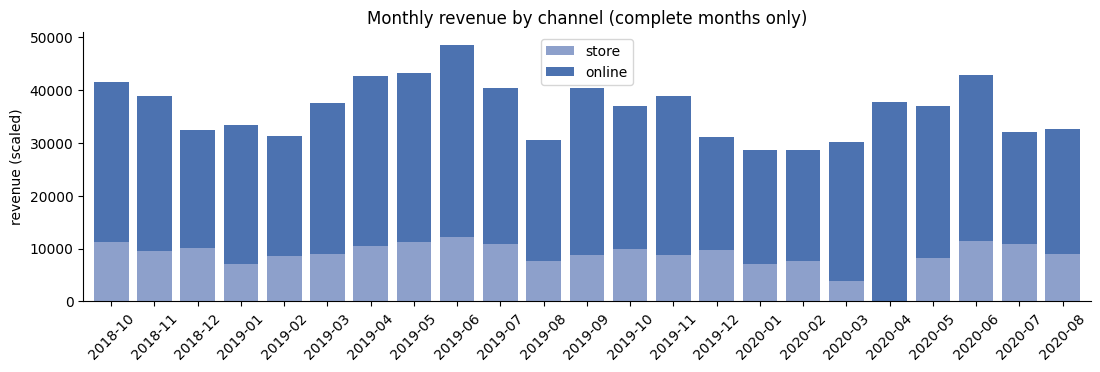

Oct 2018–Aug 2019 vs Oct 2019–Aug 2020 revenue: 0.90×
online share: year 1 74%, year 2 77%


In [7]:
tx["month"] = tx.t_dat.dt.to_period("M")
monthly = tx[(tx.t_dat >= "2018-10-01") & (tx.t_dat < "2020-09-01")].groupby(["month", "sales_channel_id"]).price.sum().unstack()
monthly.columns = ["store", "online"]
fig, ax = plt.subplots(figsize=(13, 3.5))
monthly.plot.bar(stacked=True, ax=ax, color=["#8DA0CB", "#4C72B0"], width=.8)
ax.set_xticklabels([str(m) for m in monthly.index], rotation=45)
ax.set(title="Monthly revenue by channel (complete months only)", ylabel="revenue (scaled)", xlabel="")
plt.show()

yoy = monthly.sum(axis=1)
print(f"Oct 2018–Aug 2019 vs Oct 2019–Aug 2020 revenue: {yoy['2019-10':'2020-08'].sum() / yoy['2018-10':'2019-08'].sum():.2f}×")
print(f"online share: year 1 {monthly.online['2018-10':'2019-08'].sum() / yoy['2018-10':'2019-08'].sum():.0%}, "
      f"year 2 {monthly.online['2019-10':'2020-08'].sum() / yoy['2019-10':'2020-08'].sum():.0%}")

## 3. Product performance

In [8]:
art_rev = tx.groupby("article_id").price.sum().sort_values(ascending=False)
cum = art_rev.cumsum() / art_rev.sum()
for p in [.01, .1, .2, .5]:
    print(f"top {p:.0%} of articles earn {cum.iloc[int(len(cum) * p) - 1]:.0%} of revenue")

life = tx.groupby("article_id").t_dat.agg(["min", "max"])
life["days_on_sale"] = (life["max"] - life["min"]).dt.days + 1
print(f"\ndays between an article's first and last sale: median {life.days_on_sale.median():.0f}, "
      f"25% {life.days_on_sale.quantile(.25):.0f}, 75% {life.days_on_sale.quantile(.75):.0f}")
new_each_month = life["min"].dt.to_period("M").value_counts().sort_index()
print(f"new articles first sold per month (from Oct 2018): median {new_each_month['2018-10':'2020-08'].median():.0f}")

top 1% of articles earn 18% of revenue
top 10% of articles earn 62% of revenue
top 20% of articles earn 81% of revenue
top 50% of articles earn 98% of revenue



days between an article's first and last sale: median 206, 25% 86, 75% 370
new articles first sold per month (from Oct 2018): median 3198


top 1% of styles earn 48% of revenue
top 10% of styles earn 84% of revenue
top 20% of styles earn 93% of revenue


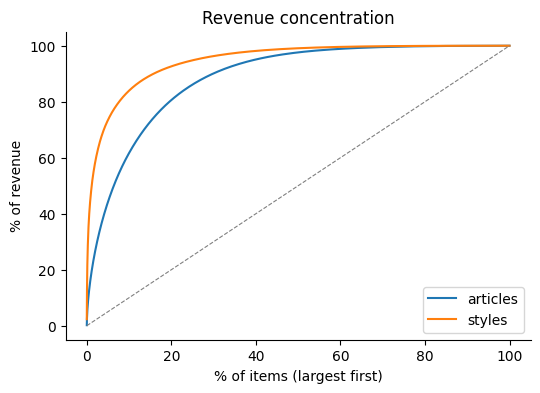

In [9]:
style_rev = tx.groupby("style_id").price.sum().sort_values(ascending=False)
cum_s = style_rev.cumsum() / style_rev.sum()
for p in [.01, .1, .2]:
    print(f"top {p:.0%} of styles earn {cum_s.iloc[int(len(cum_s) * p) - 1]:.0%} of revenue")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.linspace(0, 100, len(cum)), cum.values * 100, label="articles")
ax.plot(np.linspace(0, 100, len(cum_s)), cum_s.values * 100, label="styles")
ax.plot([0, 100], [0, 100], color="grey", ls="--", lw=.8)
ax.set(title="Revenue concentration", xlabel="% of items (largest first)", ylabel="% of revenue")
ax.legend(); plt.show()

## 4. Category performance

In [10]:
seg = tx.groupby("index_group_name").agg(revenue=("price", "sum"), units=("price", "size"),
                                         articles=("article_id", "nunique"), styles=("style_id", "nunique"))
seg["revenue share"] = seg.revenue / seg.revenue.sum()
seg["avg price"] = seg.revenue / seg.units
y1 = tx[tx.t_dat < "2019-09-20"].groupby("index_group_name").price.sum()
y2 = tx[tx.t_dat >= "2019-09-20"].groupby("index_group_name").price.sum()
seg["year 2 ÷ year 1"] = y2 / y1
seg.sort_values("revenue", ascending=False).style.format(
    {"revenue": "{:,.0f}", "units": "{:,}", "articles": "{:,}", "styles": "{:,}", "revenue share": "{:.1%}",
     "avg price": "{:.4f}", "year 2 ÷ year 1": "{:.2f}"})

,revenue,units,articles,styles,revenue share,avg price,year 2 ÷ year 1
index_group_name,,,,,,,
Ladieswear,"584,837","20,315,656","39,177","7,268",66.4%,0.0288,0.94
Divided,"188,960","7,130,209","15,015","3,648",21.4%,0.0265,0.90
Menswear,"48,347","1,759,791","12,414","3,043",5.5%,0.0275,0.93
Sport,"35,390","1,232,741","3,370","1,108",4.0%,0.0287,1.05
Baby/Children,"23,499","1,214,791","34,206","8,287",2.7%,0.0193,0.38


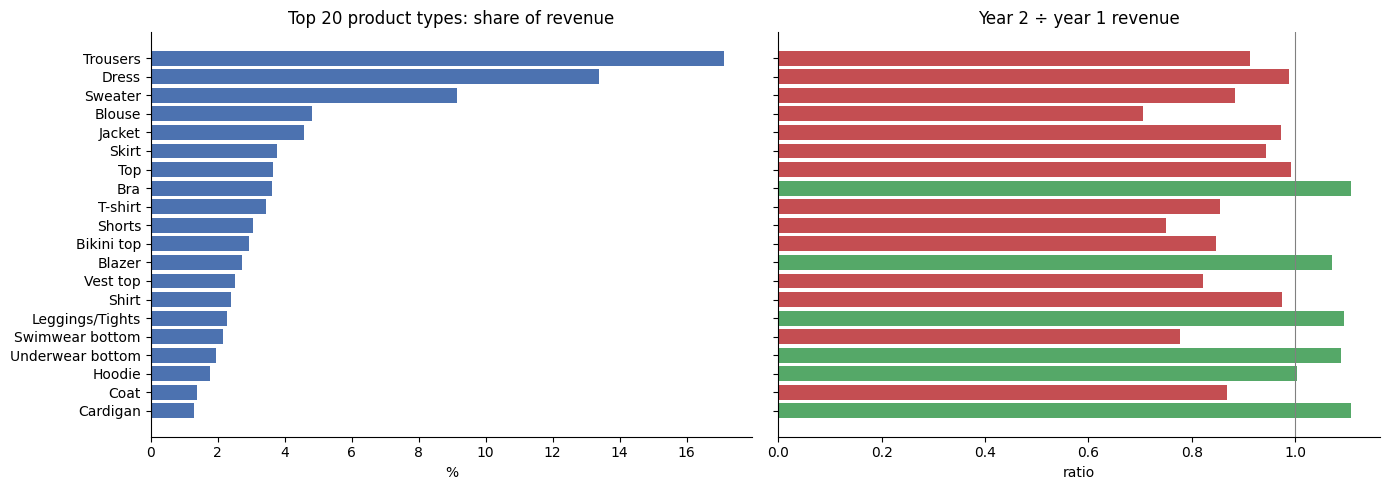

In [11]:
pt = tx.groupby("product_type_name").price.sum().sort_values(ascending=False)
top_types = pt.head(20).index
y1 = tx[tx.t_dat < "2019-09-20"].groupby("product_type_name").price.sum()
y2 = tx[tx.t_dat >= "2019-09-20"].groupby("product_type_name").price.sum()
growth = (y2 / y1).loc[top_types]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
axes[0].barh(top_types[::-1], pt.loc[top_types][::-1] / pt.sum() * 100, color="#4C72B0")
axes[0].set(title="Top 20 product types: share of revenue", xlabel="%")
axes[1].barh(top_types[::-1], growth[::-1], color=np.where(growth[::-1] >= 1, "#55A868", "#C44E52"))
axes[1].axvline(1, color="grey", lw=.8)
axes[1].set(title="Year 2 ÷ year 1 revenue", xlabel="ratio")
plt.tight_layout(); plt.show()

## 5. Customer and product behaviour

In [12]:
tx["online"] = tx.sales_channel_id.eq(2)
cust = tx.groupby("customer_id").agg(units=("price", "size"), days=("t_dat", "nunique"),
                                     styles=("style_id", "nunique"), online=("online", "mean"))
print(f"customers: {len(cust):,}")
print(f"units per customer: median {cust.units.median():.0f}, 90% {cust.units.quantile(.9):.0f}, 99% {cust.units.quantile(.99):.0f}")
print(f"shopping days per customer: median {cust.days.median():.0f}; bought on only one day: {(cust.days == 1).mean():.0%}")
print(f"distinct styles per customer: median {cust.styles.median():.0f}")
print(f"customers buying only online: {(cust.online == 1).mean():.0%}, only in store: {(cust.online == 0).mean():.0%}")
basket = tx.groupby(["customer_id", "t_dat"]).size()
print(f"units per shopping day (basket size): median {basket.median():.0f}, mean {basket.mean():.1f}")

customers: 1,361,578
units per customer: median 9, 90% 59, 99% 187
shopping days per customer: median 3; bought on only one day: 33%
distinct styles per customer: median 8
customers buying only online: 46%, only in store: 19%


units per shopping day (basket size): median 2, mean 3.5


In [13]:
# Do customers come back to the same style? (repeat purchase of a style on a different day)
cs = tx.groupby(["style_id", "customer_id"]).t_dat.nunique()
style_beh = pd.DataFrame({
    "customers": cs.groupby(level="style_id").size(),
    "repeat_rate": (cs > 1).groupby(level="style_id").mean(),
    "revenue": tx.groupby("style_id").price.sum(),
}).sort_values("revenue", ascending=False)
names = styled.drop_duplicates("style_id").set_index("style_id").style_name
top = style_beh.head(15).assign(style=lambda d: names.loc[d.index].values)
print(f"styles bought by ≥1,000 customers: {(style_beh.customers >= 1000).sum():,} of {len(style_beh):,}")
print(f"repeat rate (share of a style's customers who bought it on 2+ days), revenue-weighted: "
      f"{np.average(style_beh.repeat_rate, weights=style_beh.revenue):.0%}")
top[["style", "customers", "repeat_rate"]].style.format({"customers": "{:,}", "repeat_rate": "{:.0%}"}).hide(axis="index")

styles bought by ≥1,000 customers: 3,577 of 23,354
repeat rate (share of a style's customers who bought it on 2+ days), revenue-weighted: 11%


style,customers,repeat_rate
Ladieswear · Trousers · Solid · Black · Dark,"258,103",34%
Ladieswear · Dress · Solid · Black · Dark,"207,033",34%
Divided · Trousers · Solid · Black · Dark,"161,709",28%
Ladieswear · Jacket · Solid · Black · Dark,"68,416",18%
Ladieswear · Blouse · Solid · White · Light,"156,938",26%
Ladieswear · Bra · Solid · Black · Dark,"175,049",27%
Ladieswear · Sweater · Solid · Black · Dark,"148,172",24%
Ladieswear · Dress · All over pattern · Black · Dark,"103,681",25%
Ladieswear · Top · Solid · Black · Dark,"187,598",27%
Divided · Dress · Solid · Black · Dark,"124,419",25%


## Findings

**Data quality**
- The data is clean structurally: no missing values in transactions, no days without sales, no unknown article IDs,
  no zero or negative prices, no duplicate articles, and product codes consistent with article IDs.
- Cleaning removed 376 articles (98 non-fashion, 278 with an undefined style), keeping **99.6% of revenue**.
- Identical rows (9%) are multiple units of the same item, because there is no quantity column. They are kept.
- Very low prices and bulk purchases (up to 570 units by one customer in a day) are tiny in revenue terms and are kept.

**Sales trends**
- Year 2 revenue is 0.90× year 1. The online share of revenue is 74–77%. In April 2020 there are no store sales at all (COVID).
- **Baby/Children declines steadily**, from ~2,900/month in Oct 2018 to ~400–500/month in 2020 (year 2 ÷ year 1 = 0.38),
  across all kids' sub-segments. Other segments are at 0.90–1.05×. The success score compares styles within their category,
  so kids' rankings are not distorted, but **category trend should be a model feature**.

**Product performance**
- Revenue is concentrated: the top 10% of articles earn 62% of revenue, and the top 1% of **styles** earn 48%.
- Articles are short-lived: the median time between first and last sale is ~7 months, and ~3,200 new articles appear every month.
  This again supports predicting styles rather than articles.

**Category performance**
- Ladieswear is two thirds of revenue, then Divided (21%), Menswear (6%), Sport (4%) and Baby/Children (3%).
- Trousers (17%), dresses (13%) and sweaters (9%) lead. Bras, blazers, leggings, underwear, hoodies and cardigans grew;
  blouses, shorts and swimwear shrank most (summer 2020 was COVID-affected).

**Customer behaviour**
- 1.36M customers. The median customer buys 9 units over 3 shopping days, with a basket of 2 units. A third shop only once.
- 46% of customers buy only online and 19% only in store.
- The big basics are bought by 100k–260k customers each, and **20–34% of their buyers come back for the same style** on
  another day. Repeat purchase is a sign of a strong style and is a candidate feature.